# Assignment 05 — Transformers from Scratch in NumPy

### Mathematical foundations and implementation: attention, masking, multi-head, encoder and decoder

**Course:** AIAC 536 — Natural Language Processing
**Programme:** MTech in Artificial Intelligence, Kathmandu University
**Student:** Prasanna Koirala (Roll 20016)

---

**Rules followed throughout**
- Only **NumPy** (maths) and **Matplotlib** (plots). No PyTorch, TensorFlow, Keras or JAX.
- Nothing prebuilt: softmax, positional encoding, masks and every attention layer are written by hand below.
- Every line that changes a shape has a comment like `# (n, d_k) @ (d_k, n) -> (n, n)`.
- Every manual calculation from the handwritten notes is **checked against Python** in this notebook.

**How each question is laid out**
1. **Idea in one line**, and how we thought about it
2. **Code**
3. **Output**: intermediate matrices, then *hand value vs Python value*
4. **What this shows**: the interpretation

Every check is recorded, and the last cell prints the total.

**To run:** `uv sync --group dev --group embed`, then *Run All* with the **NLP (uv)** kernel.

In [1]:
# Only two libraries are used in this whole notebook.
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=4, suppress=True)   # print 4 decimals, no scientific notation
plt.rcParams["font.size"] = 11                    # stays readable when a plot is printed small in the notes

OUT = Path("outputs")          # plots are saved here
OUT.mkdir(exist_ok=True)

CHECKS = []                    # every verification test is recorded here: (name, passed)


def check(name, passed):
    """Record one verification test and print a tick or a cross."""
    passed = bool(passed)
    CHECKS.append((name, passed))
    if passed:
        print("  ✓ " + name)
    else:
        print("  ✗ FAILED: " + name)


def show(name, M):
    """Print a matrix together with its shape."""
    M = np.asarray(M)
    print(f"{name}   shape {M.shape}")
    print(M)
    print()


def compare(label, hand, python, decimals):
    """Hand value (from the handwritten notes) vs the Python value rounded to the same decimals."""
    hand = np.asarray(hand, dtype=float)
    rounded = np.round(np.asarray(python, dtype=float), decimals)
    print(f"{label}")
    print("   by hand:", hand.tolist())
    print("   Python :", rounded.tolist())
    check(f"{label}: hand = Python ({decimals} d.p.)", np.allclose(hand, rounded, atol=1e-9))
    print()

---
## Q1 — Sinusoidal positional encoding

**Idea in one line:** attention has no sense of word order, so every position gets a unique "where am I" tag made of sine and cosine waves, which is added to the word's vector.

**How we thought about it:** each pair of dimensions `(2i, 2i+1)` is one wave with its own speed. Pair 0 is the fastest wave and changes a lot from one word to the next; the last pair is the slowest. Together the waves give every position a unique pattern, like the hands of a clock.

$$PE(pos, 2i) = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE(pos, 2i+1) = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

In [2]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return array with shape (seq_len, d_model)."""
    # Dimensions come in (sin, cos) pairs, so d_model must be even.
    assert d_model % 2 == 0, "d_model must be even"

    pe = np.zeros((seq_len, d_model))                  # (seq_len, d_model), filled in below

    positions = np.arange(seq_len).reshape(-1, 1)      # (seq_len, 1): 0, 1, 2, ... as a column
    pair_index = np.arange(d_model // 2)               # (d_model/2,): i = 0, 1, ..., d/2 - 1

    # One divisor per (sin, cos) pair: 10000^(2i/d). Bigger i -> bigger divisor -> slower wave.
    divisors = 10000 ** (2 * pair_index / d_model)     # (d_model/2,)

    # Angle for every (position, pair). Broadcasting: (seq_len, 1) / (d_model/2,) -> (seq_len, d_model/2)
    angles = positions / divisors

    pe[:, 0::2] = np.sin(angles)                       # even columns 0, 2, 4, ... get sine
    pe[:, 1::2] = np.cos(angles)                       # odd columns 1, 3, 5, ... get cosine
    return pe

### Q1(b) — the hand calculation, checked: d = 4, positions 0, 1, 2

With d = 4 there are two pairs: `i = 0` divides by $10000^{0} = 1$ and `i = 1` divides by $10000^{2/4} = 100$.

In [3]:
d = 4
pair_index = np.arange(d // 2)
divisors = 10000 ** (2 * pair_index / d)
show("divisors 10000^(2i/d) for i = 0, 1", divisors)
show("angles pos / divisor  (rows = pos 0,1,2; cols = pair 0,1)", np.arange(3).reshape(-1, 1) / divisors)

pe_small = sinusoidal_positional_encoding(seq_len=3, d_model=4)
show("PE matrix (3 x 4)", pe_small)

# The values written in the handwritten notes (4 decimal places)
HAND_Q1B = [[0.0000,  1.0000, 0.0000, 1.0000],
            [0.8415,  0.5403, 0.0100, 1.0000],
            [0.9093, -0.4161, 0.0200, 0.9998]]
compare("Q1b PE matrix", HAND_Q1B, pe_small, decimals=4)

divisors 10000^(2i/d) for i = 0, 1   shape (2,)
[  1. 100.]

angles pos / divisor  (rows = pos 0,1,2; cols = pair 0,1)   shape (3, 2)
[[0.   0.  ]
 [1.   0.01]
 [2.   0.02]]

PE matrix (3 x 4)   shape (3, 4)
[[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]]

Q1b PE matrix
   by hand: [[0.0, 1.0, 0.0, 1.0], [0.8415, 0.5403, 0.01, 1.0], [0.9093, -0.4161, 0.02, 0.9998]]
   Python : [[0.0, 1.0, 0.0, 1.0], [0.8415, 0.5403, 0.01, 1.0], [0.9093, -0.4161, 0.02, 0.9998]]
  ✓ Q1b PE matrix: hand = Python (4 d.p.)



### Q1(c) — seq_len = 20, d_model = 16, visualised

PE shape: (20, 16)
  ✓ PE has shape (20, 16)
  ✓ position 0 is [0, 1, 0, 1, ...] (sin 0 = 0, cos 0 = 1)
  ✓ every value lies in [-1, 1]


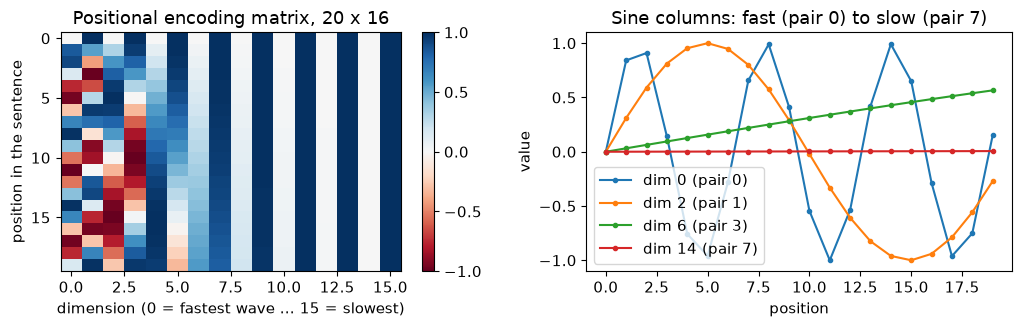

In [4]:
pe = sinusoidal_positional_encoding(seq_len=20, d_model=16)
print("PE shape:", pe.shape)
check("PE has shape (20, 16)", pe.shape == (20, 16))
check("position 0 is [0, 1, 0, 1, ...] (sin 0 = 0, cos 0 = 1)", np.allclose(pe[0], np.tile([0.0, 1.0], 8)))
check("every value lies in [-1, 1]", np.all(np.abs(pe) <= 1.0))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))

image = axes[0].imshow(pe, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
axes[0].set_xlabel("dimension (0 = fastest wave ... 15 = slowest)")
axes[0].set_ylabel("position in the sentence")
axes[0].set_title("Positional encoding matrix, 20 x 16")
fig.colorbar(image, ax=axes[0])

# Plot one sine column per chosen pair, to see fast vs slow waves directly
for pair in [0, 1, 3, 7]:
    axes[1].plot(pe[:, 2 * pair], marker="o", markersize=3, label=f"dim {2 * pair} (pair {pair})")
axes[1].set_xlabel("position")
axes[1].set_ylabel("value")
axes[1].set_title("Sine columns: fast (pair 0) to slow (pair 7)")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT / "q1c_positional_encoding.png", dpi=150)
plt.show()

### Q1(d) — periodicity and relative position

Each pair repeats every $2\pi \cdot 10000^{2i/d}$ positions (its wavelength). The key property: moving forward by $k$ positions **rotates** each (sin, cos) pair by the angle $\omega_i k$, and that rotation does not depend on where you started:

$$\begin{bmatrix}\sin\omega(p+k)\\ \cos\omega(p+k)\end{bmatrix} = \begin{bmatrix}\cos\omega k & \sin\omega k\\ -\sin\omega k & \cos\omega k\end{bmatrix}\begin{bmatrix}\sin\omega p\\ \cos\omega p\end{bmatrix}$$

In [5]:
d_model = 16
pair_index = np.arange(d_model // 2)
omegas = 1 / (10000 ** (2 * pair_index / d_model))     # (8,) speed of each pair
wavelengths = 2 * np.pi / omegas                        # (8,) positions before each pair repeats
print("wavelength of each pair (positions):", np.round(wavelengths, 1))

# Check the rotation property for every position p, every pair i, and an offset of k = 3
k = 3
all_match = True
for i in range(d_model // 2):
    angle = omegas[i] * k
    rotation = np.array([[ np.cos(angle), np.sin(angle)],
                         [-np.sin(angle), np.cos(angle)]])     # (2, 2), depends only on k
    for p in range(20 - k):
        pair_now = pe[p, 2 * i:2 * i + 2]                      # (2,) [sin, cos] at position p
        pair_later = pe[p + k, 2 * i:2 * i + 2]                # (2,) [sin, cos] at position p + k
        if not np.allclose(rotation @ pair_now, pair_later):
            all_match = False
check("PE(p + 3) is the same fixed rotation of PE(p), for every p and every pair", all_match)

wavelength of each pair (positions): [    6.3    19.9    62.8   198.7   628.3  1986.9  6283.2 19869.2]
  ✓ PE(p + 3) is the same fixed rotation of PE(p), for every p and every pair


**What this shows (Q1):**
- The left columns of the heatmap flip between red and blue almost every row. These are the **high-frequency** pairs, which tell neighbouring words apart. The right columns hardly change down the whole 20 rows (wavelengths up to about 19,869 positions). These are the **low-frequency** pairs, which say roughly *where* in a long text you are.
- Each wave is **periodic**, but because the pairs have different wavelengths, no two positions get the same full pattern.
- The rotation check passed: "3 positions later" is the same transformation everywhere. That is why the model can learn **relative** position ("the word 3 back") once and use it at any point in the sentence.

---
## Q2 — Scaled dot-product self-attention

**Idea in one line:** every word compares its query with every word's key, turns the scores into percentages with softmax, and takes that mix of the values.

**How we thought about it:** four steps, each a single line of NumPy. Scores → scale by √d_k → softmax each row → weighted sum of V.

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

In [6]:
def softmax(x, axis=-1):
    """Softmax along `axis`, written by hand.

    We subtract the largest value first. That changes nothing mathematically (proved in Q7a),
    but it stops np.exp from overflowing on large scores.
    """
    x = np.asarray(x, dtype=float)
    shifted = x - np.max(x, axis=axis, keepdims=True)    # same shape as x; the largest entry becomes 0
    exps = np.exp(shifted)                                # every entry positive; the largest is exactly 1
    return exps / np.sum(exps, axis=axis, keepdims=True)  # each slice along `axis` now sums to 1


def scaled_dot_product_attention(Q, K, V):
    """Q:(n_queries,d_k), K:(n_keys,d_k), V:(n_keys,d_v)
    Return output and attention weights.
    """
    d_k = Q.shape[1]
    assert K.shape[1] == d_k, "Q and K must have the same width d_k"
    assert K.shape[0] == V.shape[0], "every key needs a value"

    scores = Q @ K.T                     # (n_q, d_k) @ (d_k, n_k) -> (n_q, n_k): one score per (query, key)
    scaled = scores / np.sqrt(d_k)       # (n_q, n_k): keep the scores around size 1 (see Q2a)
    weights = softmax(scaled, axis=-1)   # (n_q, n_k): each row sums to 1
    output = weights @ V                 # (n_q, n_k) @ (n_k, d_v) -> (n_q, d_v): weighted mix of the values
    return output, weights


def attention_steps(Q, K, V, mask=None):
    """Every intermediate of attention, the way it is done by hand (used for printing and checking).

    By hand we compute e^x of the scaled scores directly (no max-shift), so this does the same.
    """
    d_k = Q.shape[1]
    steps = {}
    steps["QK^T"] = Q @ K.T                               # (n_q, n_k)
    steps["scaled"] = steps["QK^T"] / np.sqrt(d_k)        # (n_q, n_k)
    if mask is not None:
        steps["masked"] = steps["scaled"] + mask          # (n_q, n_k): -inf where blocked
        to_exp = steps["masked"]
    else:
        to_exp = steps["scaled"]
    steps["e^x"] = np.exp(to_exp)                         # (n_q, n_k): e^(-inf) = 0
    steps["row sums"] = steps["e^x"].sum(axis=1)          # (n_q,)
    steps["weights"] = steps["e^x"] / steps["row sums"].reshape(-1, 1)   # (n_q, n_k)
    steps["output"] = steps["weights"] @ V                # (n_q, d_v)
    return steps


def print_steps(steps):
    for name, value in steps.items():
        show(name, value)

### Q2(a) — evidence for scaling by √d_k

If the components of q and k are independent with mean 0 and variance 1, then $\text{Var}(q\cdot k) = d_k$, so the typical size of a score is $\sqrt{d_k}$. Measured:

In [7]:
rng = np.random.default_rng(0)
print("d_k   std(q.k)   sqrt(d_k)   std after dividing by sqrt(d_k)")
for d_k in [4, 64, 512]:
    q = rng.normal(size=(20000, d_k))          # 20,000 random query vectors
    k = rng.normal(size=(20000, d_k))          # 20,000 random key vectors
    dots = np.sum(q * k, axis=1)               # (20000,) one dot product per pair
    print(f"{d_k:<5} {dots.std():8.2f}   {np.sqrt(d_k):8.2f}    {(dots / np.sqrt(d_k)).std():8.2f}")

d_k   std(q.k)   sqrt(d_k)   std after dividing by sqrt(d_k)
4         2.00       2.00        1.00
64        8.03       8.00        1.00
512      22.54      22.63        1.00


### Q2(b) — the hand calculation, checked: Q = K = V = I₂

In [8]:
I2 = np.eye(2)
steps = attention_steps(I2, I2, I2)
print_steps(steps)

output, weights = scaled_dot_product_attention(I2, I2, I2)
check("attention function gives the same weights as the step-by-step version", np.allclose(weights, steps["weights"]))

# Values written in the handwritten notes (3 decimal places, as the question asks)
compare("Q2b scaled scores", [[0.707, 0.000], [0.000, 0.707]], steps["scaled"], decimals=3)
compare("Q2b attention weights", [[0.670, 0.330], [0.330, 0.670]], weights, decimals=3)
compare("Q2b output", [[0.670, 0.330], [0.330, 0.670]], output, decimals=3)

QK^T   shape (2, 2)
[[1. 0.]
 [0. 1.]]

scaled   shape (2, 2)
[[0.7071 0.    ]
 [0.     0.7071]]

e^x   shape (2, 2)
[[2.0281 1.    ]
 [1.     2.0281]]

row sums   shape (2,)
[3.0281 3.0281]

weights   shape (2, 2)
[[0.6698 0.3302]
 [0.3302 0.6698]]

output   shape (2, 2)
[[0.6698 0.3302]
 [0.3302 0.6698]]

  ✓ attention function gives the same weights as the step-by-step version
Q2b scaled scores
   by hand: [[0.707, 0.0], [0.0, 0.707]]
   Python : [[0.707, 0.0], [0.0, 0.707]]
  ✓ Q2b scaled scores: hand = Python (3 d.p.)

Q2b attention weights
   by hand: [[0.67, 0.33], [0.33, 0.67]]
   Python : [[0.67, 0.33], [0.33, 0.67]]
  ✓ Q2b attention weights: hand = Python (3 d.p.)

Q2b output
   by hand: [[0.67, 0.33], [0.33, 0.67]]
   Python : [[0.67, 0.33], [0.33, 0.67]]
  ✓ Q2b output: hand = Python (3 d.p.)



### Q2(d) — verification: every row of weights sums to 1

In [9]:
check("Q2b: each row of weights sums to 1", np.allclose(weights.sum(axis=1), 1.0))

# Also on a bigger random example: 5 queries, 7 keys, d_k = 4, d_v = 3
rng = np.random.default_rng(1)
Q_test = rng.normal(size=(5, 4))
K_test = rng.normal(size=(7, 4))
V_test = rng.normal(size=(7, 3))
out_test, w_test = scaled_dot_product_attention(Q_test, K_test, V_test)
print("weights shape:", w_test.shape, "  output shape:", out_test.shape)
print("row sums:", w_test.sum(axis=1))
check("random example: weights have shape (5, 7) and output (5, 3)", w_test.shape == (5, 7) and out_test.shape == (5, 3))
check("random example: every row of weights sums to 1", np.allclose(w_test.sum(axis=1), 1.0))

  ✓ Q2b: each row of weights sums to 1
weights shape: (5, 7)   output shape: (5, 3)
row sums: [1. 1. 1. 1. 1.]
  ✓ random example: weights have shape (5, 7) and output (5, 3)
  ✓ random example: every row of weights sums to 1


**What this shows (Q2):**
- With Q = K = V = I₂, each token matches itself (score 1) and not the other (score 0). After scaling and softmax each token gives **67% to itself and 33% to the other**. It doesn't give 100%, because softmax never gives a hard zero.
- Since V = I, the output *is* the weight matrix: each output row is literally "how much of each token was taken".
- The √d_k experiment shows why we scale: the typical score size grows exactly like √d_k (2, 8, 22.6). Dividing brings it back to 1, so softmax doesn't saturate at large d_k.

---
## Q3 — Learnable Q, K, V projections

**Idea in one line:** each word is multiplied by three learned matrices to get three different versions of itself: a query (for asking), a key (for being found) and a value (for sharing).

**How we thought about it:** $W_Q, W_K$ are $(d_{model} \times d_k)$ and must share $d_k$, because Q and K get dot-producted. $W_V$ is $(d_{model} \times d_v)$ and can have a different width.

In [10]:
def self_attention(X, W_Q, W_K, W_V):
    """Compute Q, K, V projections and attention.

    X:(n, d_model)   W_Q, W_K:(d_model, d_k)   W_V:(d_model, d_v)
    Returns output (n, d_v), weights (n, n), and the projections Q, K, V.
    """
    Q = X @ W_Q     # (n, d_model) @ (d_model, d_k) -> (n, d_k)
    K = X @ W_K     # (n, d_model) @ (d_model, d_k) -> (n, d_k)
    V = X @ W_V     # (n, d_model) @ (d_model, d_v) -> (n, d_v)
    output, weights = scaled_dot_product_attention(Q, K, V)
    return output, weights, Q, K, V

### Q3(b) — the hand calculation, checked

$X = \begin{bmatrix}1&2\\0&1\end{bmatrix},\ W_Q = \begin{bmatrix}1&0\\0&1\end{bmatrix},\ W_K = \begin{bmatrix}0&1\\1&0\end{bmatrix},\ W_V = \begin{bmatrix}2&0\\0&1\end{bmatrix}$

In [11]:
X3 = np.array([[1.0, 2.0], [0.0, 1.0]])
W_Q3 = np.array([[1.0, 0.0], [0.0, 1.0]])
W_K3 = np.array([[0.0, 1.0], [1.0, 0.0]])
W_V3 = np.array([[2.0, 0.0], [0.0, 1.0]])

out3, w3, Q3, K3, V3 = self_attention(X3, W_Q3, W_K3, W_V3)
show("Q = X W_Q", Q3)
show("K = X W_K", K3)
show("V = X W_V", V3)
steps3 = attention_steps(Q3, K3, V3)
print_steps(steps3)

compare("Q3b Q", [[1, 2], [0, 1]], Q3, decimals=0)
compare("Q3b K", [[2, 1], [1, 0]], K3, decimals=0)
compare("Q3b V", [[2, 2], [0, 1]], V3, decimals=0)
compare("Q3b scores QK^T", [[4, 1], [1, 0]], steps3["QK^T"], decimals=0)
compare("Q3b scaled scores", [[2.828, 0.707], [0.707, 0.000]], steps3["scaled"], decimals=3)
compare("Q3b attention weights", [[0.893, 0.107], [0.670, 0.330]], w3, decimals=3)
compare("Q3b output", [[1.786, 1.893], [1.340, 1.670]], out3, decimals=3)

Q = X W_Q   shape (2, 2)
[[1. 2.]
 [0. 1.]]

K = X W_K   shape (2, 2)
[[2. 1.]
 [1. 0.]]

V = X W_V   shape (2, 2)
[[2. 2.]
 [0. 1.]]

QK^T   shape (2, 2)
[[4. 1.]
 [1. 0.]]

scaled   shape (2, 2)
[[2.8284 0.7071]
 [0.7071 0.    ]]

e^x   shape (2, 2)
[[16.9188  2.0281]
 [ 2.0281  1.    ]]

row sums   shape (2,)
[18.9469  3.0281]

weights   shape (2, 2)
[[0.893  0.107 ]
 [0.6698 0.3302]]

output   shape (2, 2)
[[1.7859 1.893 ]
 [1.3395 1.6698]]

Q3b Q
   by hand: [[1.0, 2.0], [0.0, 1.0]]
   Python : [[1.0, 2.0], [0.0, 1.0]]
  ✓ Q3b Q: hand = Python (0 d.p.)

Q3b K
   by hand: [[2.0, 1.0], [1.0, 0.0]]
   Python : [[2.0, 1.0], [1.0, 0.0]]
  ✓ Q3b K: hand = Python (0 d.p.)

Q3b V
   by hand: [[2.0, 2.0], [0.0, 1.0]]
   Python : [[2.0, 2.0], [0.0, 1.0]]
  ✓ Q3b V: hand = Python (0 d.p.)

Q3b scores QK^T
   by hand: [[4.0, 1.0], [1.0, 0.0]]
   Python : [[4.0, 1.0], [1.0, 0.0]]
  ✓ Q3b scores QK^T: hand = Python (0 d.p.)

Q3b scaled scores
   by hand: [[2.828, 0.707], [0.707, 0.0]]
   Python

### Q3(d) — identity projections vs the supplied projections

In [12]:
out_id, w_id, _, _, _ = self_attention(X3, np.eye(2), np.eye(2), np.eye(2))
steps_id = attention_steps(X3, X3, X3)

show("scores with identity projections", steps_id["QK^T"])
show("scores with supplied projections", steps3["QK^T"])
difference = steps_id["QK^T"] - steps3["QK^T"]
show("difference (identity - supplied)", difference)

check("each row of scores shifted by one constant (here +1 in both rows)",
      np.allclose(difference, difference[:, [0]]))
check("so the attention weights are IDENTICAL", np.allclose(w_id, w3))
check("but the outputs are DIFFERENT (W_V changed the values)", not np.allclose(out_id, out3))
show("weights (identity = supplied)", w_id)
show("output, identity projections", out_id)
show("output, supplied projections", out3)
compare("Q3d identity output", [[0.893, 1.893], [0.670, 1.670]], out_id, decimals=3)

# In general a projection DOES change the weights. Try a random W_K:
rng = np.random.default_rng(2)
W_K_random = rng.normal(size=(2, 2))
_, w_random, _, _, _ = self_attention(X3, np.eye(2), W_K_random, np.eye(2))
show("weights with a random W_K", w_random)
check("a random W_K changes the attention weights", not np.allclose(w_random, w_id))

scores with identity projections   shape (2, 2)
[[5. 2.]
 [2. 1.]]

scores with supplied projections   shape (2, 2)
[[4. 1.]
 [1. 0.]]

difference (identity - supplied)   shape (2, 2)
[[1. 1.]
 [1. 1.]]

  ✓ each row of scores shifted by one constant (here +1 in both rows)
  ✓ so the attention weights are IDENTICAL
  ✓ but the outputs are DIFFERENT (W_V changed the values)
weights (identity = supplied)   shape (2, 2)
[[0.893  0.107 ]
 [0.6698 0.3302]]

output, identity projections   shape (2, 2)
[[0.893  1.893 ]
 [0.6698 1.6698]]

output, supplied projections   shape (2, 2)
[[1.7859 1.893 ]
 [1.3395 1.6698]]

Q3d identity output
   by hand: [[0.893, 1.893], [0.67, 1.67]]
   Python : [[0.893, 1.893], [0.67, 1.67]]
  ✓ Q3d identity output: hand = Python (3 d.p.)

weights with a random W_K   shape (2, 2)
[[0.0127 0.9873]
 [0.1095 0.8905]]

  ✓ a random W_K changes the attention weights


**What this shows (Q3):**
- The supplied $W_K$ swaps the two features, which changes the scores from `[[5,2],[2,1]]` to `[[4,1],[1,0]]`. Every row drops by **exactly 1**, and softmax ignores a constant added to a whole row (the same fact proved in Q7a). So **who attends to whom does not change**: the weights are identical.
- What *does* change is the **output**: $W_V$ doubles the first feature of every value, so the first output column doubles (0.893 → 1.786, 0.670 → 1.340).
- This only happens because both rows of X have $x_2 - x_1 = 1$. With a random $W_K$ the weights change, which is the normal case: **projections reshape token relationships**, because $W_Q$ and $W_K$ decide *what counts as a match*, and $W_V$ decides *what information is passed on*.

---
## Q4 — Causal self-attention and masking

**Idea in one line:** when generating text, a word may only look at itself and earlier words, so we add −∞ to every "future" score before softmax, which turns those weights into exactly 0.

**How we thought about it:** build the mask by comparing positions. Key position j is in the future of query position i when `j > i`. No library masking function is used.

In [13]:
def causal_mask(n):
    """(n, n) mask: 0 where key j <= query i (allowed), -inf where j > i (the future)."""
    i = np.arange(n).reshape(-1, 1)     # (n, 1): query positions, as a column
    j = np.arange(n).reshape(1, -1)     # (1, n): key positions, as a row
    future = j > i                      # (n, n): True above the diagonal (broadcast comparison)
    return np.where(future, -np.inf, 0.0)


def causal_self_attention(Q, K, V):
    """Return causally masked attention output and weights."""
    n, d_k = Q.shape
    assert K.shape[0] == n, "causal attention compares a sequence with itself"

    scores = Q @ K.T / np.sqrt(d_k)      # (n, d_k) @ (d_k, n) -> (n, n)
    masked = scores + causal_mask(n)     # (n, n): future entries become -inf
    weights = softmax(masked, axis=-1)   # (n, n): e^(-inf) = 0, so future weights are exactly 0
    output = weights @ V                 # (n, n) @ (n, d_v) -> (n, d_v)
    return output, weights


show("4 x 4 causal mask", causal_mask(4))

4 x 4 causal mask   shape (4, 4)
[[  0. -inf -inf -inf]
 [  0.   0. -inf -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0.   0.]]



### Q4(b) — the hand calculation, checked: Q = K = V = [[1,0],[0,1],[1,1]]

In [14]:
Z = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
steps4 = attention_steps(Z, Z, Z, mask=causal_mask(3))
print_steps(steps4)
out4, w4 = causal_self_attention(Z, Z, Z)
check("causal function agrees with the step-by-step version", np.allclose(w4, steps4["weights"]))

compare("Q4b scaled scores", [[0.707, 0.000, 0.707], [0.000, 0.707, 0.707], [0.707, 0.707, 1.414]],
        steps4["scaled"], decimals=3)
compare("Q4b token 1 probabilities", [1.000, 0.000, 0.000], w4[0], decimals=3)
compare("Q4b token 2 probabilities", [0.330, 0.670, 0.000], w4[1], decimals=3)
compare("Q4b token 3 probabilities (extra)", [0.248, 0.248, 0.503], w4[2], decimals=3)
compare("Q4b output", [[1.000, 0.000], [0.330, 0.670], [0.752, 0.752]], out4, decimals=3)

QK^T   shape (3, 3)
[[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]

scaled   shape (3, 3)
[[0.7071 0.     0.7071]
 [0.     0.7071 0.7071]
 [0.7071 0.7071 1.4142]]

masked   shape (3, 3)
[[0.7071   -inf   -inf]
 [0.     0.7071   -inf]
 [0.7071 0.7071 1.4142]]

e^x   shape (3, 3)
[[2.0281 0.     0.    ]
 [1.     2.0281 0.    ]
 [2.0281 2.0281 4.1133]]

row sums   shape (3,)
[2.0281 3.0281 8.1695]

weights   shape (3, 3)
[[1.     0.     0.    ]
 [0.3302 0.6698 0.    ]
 [0.2483 0.2483 0.5035]]

output   shape (3, 2)
[[1.     0.    ]
 [0.3302 0.6698]
 [0.7517 0.7517]]

  ✓ causal function agrees with the step-by-step version
Q4b scaled scores
   by hand: [[0.707, 0.0, 0.707], [0.0, 0.707, 0.707], [0.707, 0.707, 1.414]]
   Python : [[0.707, 0.0, 0.707], [0.0, 0.707, 0.707], [0.707, 0.707, 1.414]]
  ✓ Q4b scaled scores: hand = Python (3 d.p.)

Q4b token 1 probabilities
   by hand: [1.0, 0.0, 0.0]
   Python : [1.0, 0.0, 0.0]
  ✓ Q4b token 1 probabilities: hand = Python (3 d.p.)

Q4b token 2 probabilitie

### Q4(d) — verification, and causal vs padding masks

In [15]:
n = 5
future = np.arange(n).reshape(1, -1) > np.arange(n).reshape(-1, 1)    # (n, n) True where j > i

rng = np.random.default_rng(3)
X4 = rng.normal(size=(n, 4))
out_a, w_a = causal_self_attention(X4, X4, X4)
show("causal weights for 5 random tokens", w_a)
check("every future-token weight is exactly 0", np.all(w_a[future] == 0.0))
check("every row still sums to 1", np.allclose(w_a.sum(axis=1), 1.0))

# Strongest test: change the LAST token; the outputs of all earlier tokens must not move.
X4_changed = X4.copy()
X4_changed[-1] = X4_changed[-1] + 10.0
out_b, _ = causal_self_attention(X4_changed, X4_changed, X4_changed)
check("changing a future token leaves every earlier output unchanged", np.allclose(out_a[:-1], out_b[:-1]))

# A padding mask is different: it hides blank filler tokens (here the last 2 of 5) from EVERY row.
is_padding = np.array([False, False, False, True, True])               # (n,)
padding_mask = np.where(is_padding, -np.inf, 0.0).reshape(1, -1)       # (1, n): broadcasts to every row
w_pad = softmax(X4 @ X4.T / np.sqrt(4) + padding_mask, axis=-1)        # (n, n)
show("weights with a padding mask (last 2 tokens are padding)", w_pad)
check("padding mask: the padding columns get 0 weight in every row", np.all(w_pad[:, is_padding] == 0.0))

causal weights for 5 random tokens   shape (5, 5)
[[1.     0.     0.     0.     0.    ]
 [0.0609 0.9391 0.     0.     0.    ]
 [0.     0.0018 0.9982 0.     0.    ]
 [0.2009 0.4425 0.045  0.3115 0.    ]
 [0.4512 0.0563 0.0992 0.0999 0.2934]]

  ✓ every future-token weight is exactly 0
  ✓ every row still sums to 1
  ✓ changing a future token leaves every earlier output unchanged
weights with a padding mask (last 2 tokens are padding)   shape (5, 5)
[[0.9978 0.0022 0.     0.     0.    ]
 [0.0567 0.8745 0.0688 0.     0.    ]
 [0.     0.0018 0.9982 0.     0.    ]
 [0.2918 0.6428 0.0654 0.     0.    ]
 [0.7437 0.0928 0.1635 0.     0.    ]]

  ✓ padding mask: the padding columns get 0 weight in every row


**What this shows (Q4):**
- Token 1 can only see itself, so it gets **100%**. Token 2 splits **33% / 67%** between token 1 and itself. Every weight above the diagonal is exactly 0.
- The change-the-future test is the real proof: making the last token completely different did not move a single earlier output. That is what makes training for **autoregressive generation** honest: the model can never cheat by reading the word it is supposed to predict.
- **Causal vs padding:** the causal mask hides a *triangle* (the future, different for every row). The padding mask hides *columns* (blank filler, the same for every row). Same −∞ trick, different reason.
- (Token 3's row sums to 0.999 at 3 d.p. only because of rounding: 0.248 + 0.248 + 0.503. In Python it is exactly 1.)

---
## Q5 — Cross-attention in encoder–decoder Transformers

**Idea in one line:** the same attention, but the queries come from the decoder (the sentence being written) and the keys and values come from the encoder (the source sentence).

**How we thought about it:** only the *inputs* change: `Q = H_decoder W_Q`, `K = H_encoder W_K`, `V = H_encoder W_V`. The weight matrix becomes (n decoder tokens × m encoder tokens), which is usually not square.

In [16]:
def cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V):
    """Return cross-attention outputs and weights.

    decoder_states:(n, d_model)   encoder_states:(m, d_model)
    """
    Q = decoder_states @ W_Q     # (n, d_model) @ (d_model, d_k) -> (n, d_k): questions from the decoder
    K = encoder_states @ W_K     # (m, d_model) @ (d_model, d_k) -> (m, d_k): labels from the encoder
    V = encoder_states @ W_V     # (m, d_model) @ (d_model, d_v) -> (m, d_v): content from the encoder
    output, weights = scaled_dot_product_attention(Q, K, V)    # weights (n, m), output (n, d_v)
    return output, weights

### Q5(b) — the hand calculation, checked

Q5(b) gives Q, K and V directly (no projection matrices), so they go straight into the attention core that `cross_attention` uses.

In [17]:
Q5 = np.array([[1.0, 0.0]])                              # (1, 2): one decoder token
K5 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])      # (3, 2): three encoder tokens
V5 = np.array([[2.0, 0.0], [0.0, 2.0], [1.0, 1.0]])      # (3, 2)
steps5 = attention_steps(Q5, K5, V5)
print_steps(steps5)
out5, w5 = scaled_dot_product_attention(Q5, K5, V5)

compare("Q5b scaled scores", [[0.707, 0.000, 0.707]], steps5["scaled"], decimals=3)
compare("Q5b attention weights", [[0.401, 0.198, 0.401]], w5, decimals=3)
compare("Q5b output", [[1.203, 0.797]], out5, decimals=3)
check("Q5b weights are 1 x 3: not square", w5.shape == (1, 3))

QK^T   shape (1, 3)
[[1. 0. 1.]]

scaled   shape (1, 3)
[[0.7071 0.     0.7071]]

e^x   shape (1, 3)
[[2.0281 1.     2.0281]]

row sums   shape (1,)
[5.0562]

weights   shape (1, 3)
[[0.4011 0.1978 0.4011]]

output   shape (1, 2)
[[1.2033 0.7967]]

Q5b scaled scores
   by hand: [[0.707, 0.0, 0.707]]
   Python : [[0.707, 0.0, 0.707]]
  ✓ Q5b scaled scores: hand = Python (3 d.p.)

Q5b attention weights
   by hand: [[0.401, 0.198, 0.401]]
   Python : [[0.401, 0.198, 0.401]]
  ✓ Q5b attention weights: hand = Python (3 d.p.)

Q5b output
   by hand: [[1.203, 0.797]]
   Python : [[1.203, 0.797]]
  ✓ Q5b output: hand = Python (3 d.p.)

  ✓ Q5b weights are 1 x 3: not square


### Q5(c) — the full function: 3 decoder tokens attending to 5 encoder tokens

In [18]:
rng = np.random.default_rng(4)
d_model = 8
decoder_states = rng.normal(size=(3, d_model))     # 3 tokens written so far
encoder_states = rng.normal(size=(5, d_model))     # 5 source tokens
W_Q5 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)
W_K5 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)
W_V5 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)

out_c, w_c = cross_attention(decoder_states, encoder_states, W_Q5, W_K5, W_V5)
show("cross-attention weights (3 decoder rows x 5 encoder columns)", w_c)
print("output shape:", out_c.shape)
check("weights are (3, 5): n decoder x m encoder", w_c.shape == (3, 5))
check("output is (3, 8): one vector per DECODER token", out_c.shape == (3, 8))
check("every row sums to 1", np.allclose(w_c.sum(axis=1), 1.0))
print("source token each decoder token relies on most:", np.argmax(w_c, axis=1))

cross-attention weights (3 decoder rows x 5 encoder columns)   shape (3, 5)
[[0.0796 0.5235 0.1283 0.0474 0.2212]
 [0.0746 0.2259 0.1313 0.081  0.4873]
 [0.7665 0.1254 0.016  0.0356 0.0566]]

output shape: (3, 8)
  ✓ weights are (3, 5): n decoder x m encoder
  ✓ output is (3, 8): one vector per DECODER token
  ✓ every row sums to 1
source token each decoder token relies on most: [1 4 0]


**What this shows (Q5):**
- In Q5(b) the decoder token `[1, 0]` matches encoder tokens 1 and 3 equally (score 1) and token 2 not at all (score 0). So it takes **40% / 20% / 40%** and retrieves the mix `[1.203, 0.797]`. That is **source-information retrieval**: the decoder *looks things up* in the source sentence.
- The weights are **(n × m)**, one row per decoder token and one column per source token. The two sentences have different lengths, so there's no reason for the matrix to be square (1 × 3 and 3 × 5 here). Each row is still a probability distribution over the source.
- The output has one row per **decoder** token: cross-attention enriches the sentence being written with information pulled from the source.

---
## Q6 — Multi-head attention

**Idea in one line:** split the projected Q, K, V into H smaller pieces (heads), run attention in each piece separately, put the head outputs side by side, and mix them with $W_O$.

**How we thought about it:** head h owns columns `h·d_k ... (h+1)·d_k` of Q, K, V. Each head is just Q2's attention (or Q4's, if causal). The size of one head is worked out from the projection width, so the same code runs the toy example in Q6(b) and the d_model = 8 example.

One general function does the work. `multi_head_attention` keeps the exact signature the assignment asks for. Q9 reuses the general version for masked attention and cross-attention.

In [19]:
def mha_general(X_q, X_kv, W_Q, W_K, W_V, W_O, num_heads, causal=False):
    """Multi-head attention: queries from X_q, keys and values from X_kv.

    Self-attention: X_q = X_kv.  Cross-attention: X_q = decoder, X_kv = encoder.
    causal=True blocks future positions (only for self-attention).
    Returns output (n_q, W_O columns) and weights (num_heads, n_q, n_kv).
    """
    # 1. Project
    Q = X_q @ W_Q       # (n_q, d_model) @ (d_model, H*d_k) -> (n_q, H*d_k)
    K = X_kv @ W_K      # (n_kv, d_model) @ (d_model, H*d_k) -> (n_kv, H*d_k)
    V = X_kv @ W_V      # (n_kv, d_model) @ (d_model, H*d_v) -> (n_kv, H*d_v)

    # 2. Size of one head, from the projection widths
    assert Q.shape[1] % num_heads == 0 and V.shape[1] % num_heads == 0
    d_k = Q.shape[1] // num_heads
    d_v = V.shape[1] // num_heads

    head_outputs = []
    head_weights = []
    for h in range(num_heads):
        # 3. Split: head h owns its own block of columns
        Q_h = Q[:, h * d_k:(h + 1) * d_k]     # (n_q, d_k)
        K_h = K[:, h * d_k:(h + 1) * d_k]     # (n_kv, d_k)
        V_h = V[:, h * d_v:(h + 1) * d_v]     # (n_kv, d_v)

        # 4. Each head is ordinary attention (reusing Q2, or Q4 when causal)
        if causal:
            out_h, w_h = causal_self_attention(Q_h, K_h, V_h)
        else:
            out_h, w_h = scaled_dot_product_attention(Q_h, K_h, V_h)
        head_outputs.append(out_h)            # (n_q, d_v)
        head_weights.append(w_h)              # (n_q, n_kv)

    # 5. Concatenate the heads side by side
    concat = np.concatenate(head_outputs, axis=1)    # (n_q, H*d_v)
    # 6. The output projection mixes information across heads
    output = concat @ W_O                            # (n_q, H*d_v) @ (H*d_v, d_out) -> (n_q, d_out)
    weights = np.stack(head_weights)                 # (H, n_q, n_kv)
    return output, weights


def multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads):
    """Return output (seq_len,d_model) and weights
    (num_heads,seq_len,seq_len).
    """
    return mha_general(X, X, W_Q, W_K, W_V, W_O, num_heads, causal=False)

### Q6(a) — every shape, for d_model = 8, H = 2, d_k = d_v = 4 (5 tokens)

In [20]:
rng = np.random.default_rng(5)
n, d_model, H = 5, 8, 2
X6 = rng.normal(size=(n, d_model))
W_Q6 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)
W_K6 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)
W_V6 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)
W_O6 = rng.normal(size=(d_model, d_model)) / np.sqrt(d_model)

d_k = d_model // H
Q_full = X6 @ W_Q6
print(f"X                       {X6.shape}")
print(f"W_Q, W_K, W_V, W_O      {W_Q6.shape} each  (= {H} heads x {d_k} columns)")
print(f"Q = X W_Q               {Q_full.shape}")
print(f"Q of one head           {Q_full[:, :d_k].shape}")
print(f"scores of one head      {(Q_full[:, :d_k] @ Q_full[:, :d_k].T).shape}")

out6, w6 = multi_head_attention(X6, W_Q6, W_K6, W_V6, W_O6, num_heads=H)
print(f"one head's output       {(n, d_k)}")
print(f"concat of {H} heads       {(n, H * d_k)}")
print(f"final output            {out6.shape}")
print(f"all attention weights   {w6.shape}")
check("Q6: output is (seq_len, d_model) = (5, 8)", out6.shape == (5, 8))
check("Q6: weights are (num_heads, seq_len, seq_len) = (2, 5, 5)", w6.shape == (2, 5, 5))
check("Q6: every head's rows sum to 1", np.allclose(w6.sum(axis=2), 1.0))

X                       (5, 8)
W_Q, W_K, W_V, W_O      (8, 8) each  (= 2 heads x 4 columns)
Q = X W_Q               (5, 8)
Q of one head           (5, 4)
scores of one head      (5, 5)
one head's output       (5, 4)
concat of 2 heads       (5, 8)
final output            (5, 8)
all attention weights   (2, 5, 5)
  ✓ Q6: output is (seq_len, d_model) = (5, 8)
  ✓ Q6: weights are (num_heads, seq_len, seq_len) = (2, 5, 5)
  ✓ Q6: every head's rows sum to 1


### Q6(b) — the hand calculation, checked

$X = I_2$. Head 1: $W_Q = W_K = W_V = I_2$. Head 2: $W_Q = W_K = P = \begin{bmatrix}0&1\\1&0\end{bmatrix}$, $W_V = I_2$.
Stacked side by side as the function expects: $W_Q = W_K = [\,I_2 \mid P\,]$ and $W_V = [\,I_2 \mid I_2\,]$, each (2 × 4), so each head is 2 wide ($d_k = 2$, scale by √2).
No output projection is needed by hand, so we pass $W_O = I_4$: then the output *is* the concatenation.

In [21]:
X_toy = np.eye(2)
P = np.array([[0.0, 1.0], [1.0, 0.0]])
W_Q_toy = np.hstack([np.eye(2), P])          # (2, 4): [head 1 | head 2]
W_K_toy = np.hstack([np.eye(2), P])          # (2, 4)
W_V_toy = np.hstack([np.eye(2), np.eye(2)])  # (2, 4)
W_O_toy = np.eye(4)                          # (4, 4): leaves the concat unchanged

concat_toy, w_toy = multi_head_attention(X_toy, W_Q_toy, W_K_toy, W_V_toy, W_O_toy, num_heads=2)
show("head 1 weights", w_toy[0])
show("head 2 weights", w_toy[1])
show("P P^T", P @ P.T)
show("concat [head 1 | head 2]", concat_toy)

check("P P^T = I, so head 2's scores equal head 1's", np.allclose(P @ P.T, np.eye(2)))
check("the two heads have IDENTICAL weights", np.allclose(w_toy[0], w_toy[1]))
compare("Q6b head 1 weights", [[0.670, 0.330], [0.330, 0.670]], w_toy[0], decimals=3)
compare("Q6b head 2 weights", [[0.670, 0.330], [0.330, 0.670]], w_toy[1], decimals=3)
compare("Q6b concat", [[0.670, 0.330, 0.670, 0.330], [0.330, 0.670, 0.330, 0.670]], concat_toy, decimals=3)
check("concat is (2, 4): wider than d_model = 2, which is why W_O exists", concat_toy.shape == (2, 4))

head 1 weights   shape (2, 2)
[[0.6698 0.3302]
 [0.3302 0.6698]]

head 2 weights   shape (2, 2)
[[0.6698 0.3302]
 [0.3302 0.6698]]

P P^T   shape (2, 2)
[[1. 0.]
 [0. 1.]]

concat [head 1 | head 2]   shape (2, 4)
[[0.6698 0.3302 0.6698 0.3302]
 [0.3302 0.6698 0.3302 0.6698]]

  ✓ P P^T = I, so head 2's scores equal head 1's
  ✓ the two heads have IDENTICAL weights
Q6b head 1 weights
   by hand: [[0.67, 0.33], [0.33, 0.67]]
   Python : [[0.67, 0.33], [0.33, 0.67]]
  ✓ Q6b head 1 weights: hand = Python (3 d.p.)

Q6b head 2 weights
   by hand: [[0.67, 0.33], [0.33, 0.67]]
   Python : [[0.67, 0.33], [0.33, 0.67]]
  ✓ Q6b head 2 weights: hand = Python (3 d.p.)

Q6b concat
   by hand: [[0.67, 0.33, 0.67, 0.33], [0.33, 0.67, 0.33, 0.67]]
   Python : [[0.67, 0.33, 0.67, 0.33], [0.33, 0.67, 0.33, 0.67]]
  ✓ Q6b concat: hand = Python (3 d.p.)

  ✓ concat is (2, 4): wider than d_model = 2, which is why W_O exists


### Q6(c) — correctness tests

In [22]:
# Test 1: one head is just ordinary attention (with W_O = I)
out_1head, _ = multi_head_attention(X6, W_Q6, W_K6, W_V6, np.eye(d_model), num_heads=1)
out_plain, _, _, _, _ = self_attention(X6, W_Q6, W_K6, W_V6)
check("1 head = plain self-attention", np.allclose(out_1head, out_plain))

# Test 2: the column-slicing split equals a reshape-based split done all at once
Q = X6 @ W_Q6
K = X6 @ W_K6
V = X6 @ W_V6
Q_heads = Q.reshape(n, H, d_k).transpose(1, 0, 2)               # (n, H*d_k) -> (H, n, d_k)
K_heads = K.reshape(n, H, d_k).transpose(1, 0, 2)               # (H, n, d_k)
V_heads = V.reshape(n, H, d_k).transpose(1, 0, 2)               # (H, n, d_v)
scores = Q_heads @ K_heads.transpose(0, 2, 1) / np.sqrt(d_k)    # (H, n, d_k) @ (H, d_k, n) -> (H, n, n)
heads = softmax(scores, axis=-1) @ V_heads                      # (H, n, n) @ (H, n, d_v) -> (H, n, d_v)
concat = heads.transpose(1, 0, 2).reshape(n, H * d_k)           # (H, n, d_v) -> (n, H*d_v)
check("reshape split gives the same output as the per-head loop", np.allclose(concat @ W_O6, out6))

  ✓ 1 head = plain self-attention
  ✓ reshape split gives the same output as the per-head loop


### Q6(d) — evidence: more heads, same budget, thinner heads

In [23]:
rng = np.random.default_rng(6)
d_model = 8
X_rank = rng.normal(size=(10, d_model))        # 10 tokens
W_Q_r = rng.normal(size=(d_model, d_model))
W_K_r = rng.normal(size=(d_model, d_model))
print("heads  d_k  parameters (W_Q+W_K+W_V+W_O)  rank of one head's 10x10 score matrix")
ranks_ok = True
for H_try in [1, 2, 4, 8]:
    d_k_try = d_model // H_try
    params = 4 * d_model * d_model              # the four matrices are d_model x d_model whatever H is
    Q_h = (X_rank @ W_Q_r)[:, :d_k_try]         # (10, d_k) first head
    K_h = (X_rank @ W_K_r)[:, :d_k_try]         # (10, d_k)
    rank = np.linalg.matrix_rank(Q_h @ K_h.T)   # (10, 10) score matrix
    print(f"{H_try:>5} {d_k_try:>4} {params:>18} {rank:>28}")
    if rank != d_k_try:
        ranks_ok = False
check("parameter count is the same for every number of heads", True)
check("one head's score matrix has rank d_k: more heads means thinner heads", ranks_ok)

heads  d_k  parameters (W_Q+W_K+W_V+W_O)  rank of one head's 10x10 score matrix
    1    8                256                            8
    2    4                256                            4
    4    2                256                            2
    8    1                256                            1
  ✓ parameter count is the same for every number of heads
  ✓ one head's score matrix has rank d_k: more heads means thinner heads


**What this shows (Q6):**
- **Shapes:** X (n × 8) → Q, K, V (n × 8) → split into 2 heads of (n × 4) → each head gives weights (n × n) and output (n × 4) → concat (n × 8) → × $W_O$ → (n × 8). Weights for all heads: (2 × n × n).
- **The toy:** head 2's swap matrix cancels out, $QK^\top = XPP^\top X^\top = XX^\top$ because $PP^\top = I$, so both heads produce **identical** weights `[[0.670, 0.330], [0.330, 0.670]]`. Two heads doing one job.
- **Why heads can learn different relationships:** each head has its own $W_Q^{(h)}, W_K^{(h)}$, so each defines its own notion of "a match" (in trained models, e.g. one head follows syntax, another nearby words).
- **Why more heads ≠ more capacity:** (1) the parameter count is **fixed** at $4d^2$ whatever H is; (2) each head is **thinner**: its score matrix has rank only $d_k = d/H$ (8 → 4 → 2 → 1 above); (3) heads can be **redundant**, as in the toy. Trained models often keep their quality after many heads are removed (Michel et al. 2019; Voita et al. 2019).

---
## Q7 — Numerical stability and attention temperature

**Idea in one line:** subtracting the largest score before exponentiating changes nothing mathematically but stops overflow. Dividing scores by a temperature T controls how sharp attention is.

**How we thought about it:** $\text{softmax}(z - c)_i = \dfrac{e^{-c}e^{z_i}}{e^{-c}\sum_j e^{z_j}} = \text{softmax}(z)_i$. The factor $e^{-c}$ cancels. With $c = \max z$, the largest exponent is $e^0 = 1$.

In [24]:
def naive_softmax(x):
    """Softmax straight from the formula, with no shift. Only here to show it breaking."""
    exps = np.exp(x)
    return exps / exps.sum()


def stable_softmax(x, axis=-1):
    """Numerically stable NumPy softmax."""
    x = np.asarray(x, dtype=float)
    shifted = x - np.max(x, axis=axis, keepdims=True)    # the largest entry becomes 0, so exp never overflows
    exps = np.exp(shifted)                                # values in (0, 1]
    return exps / np.sum(exps, axis=axis, keepdims=True)

### Q7(b) — test on [1000, 1001, 1002]

In [25]:
z = np.array([1000.0, 1001.0, 1002.0])

with np.errstate(over="ignore", invalid="ignore"):     # silence the warnings; we want to SEE the failure
    print("direct exp(z)        :", np.exp(z))
    naive_result = naive_softmax(z)
print("naive softmax        :", naive_result)

shifted = z - z.max()
print("shifted z - max(z)   :", shifted)
print("exp(shifted)         :", np.exp(shifted))
stable_result = stable_softmax(z)
print("stable softmax       :", stable_result)

check("naive softmax breaks: every entry is nan", np.all(np.isnan(naive_result)))
check("stable softmax is finite and sums to 1", np.all(np.isfinite(stable_result)) and np.isclose(stable_result.sum(), 1.0))
compare("Q7b stable softmax", [0.090, 0.245, 0.665], stable_result, decimals=3)

rng = np.random.default_rng(7)
z_random = rng.normal(size=6)
check("shift invariance: softmax(z) = softmax(z + 50)", np.allclose(stable_softmax(z_random), stable_softmax(z_random + 50)))
check("stable_softmax matches the softmax used since Q2", np.allclose(stable_softmax(z_random), softmax(z_random)))

direct exp(z)        : [inf inf inf]
naive softmax        : [nan nan nan]
shifted z - max(z)   : [-2. -1.  0.]
exp(shifted)         : [0.1353 0.3679 1.    ]
stable softmax       : [0.09   0.2447 0.6652]
  ✓ naive softmax breaks: every entry is nan
  ✓ stable softmax is finite and sums to 1
Q7b stable softmax
   by hand: [0.09, 0.245, 0.665]
   Python : [0.09, 0.245, 0.665]
  ✓ Q7b stable softmax: hand = Python (3 d.p.)

  ✓ shift invariance: softmax(z) = softmax(z + 50)
  ✓ stable_softmax matches the softmax used since Q2


### Q7(c) — temperature: weights for QKᵀ/T, T ∈ {0.5, 1, 2, 4}

Six tokens with random Q and K (d_k = 8, fixed seed). We plot how query token 0 spreads its attention.

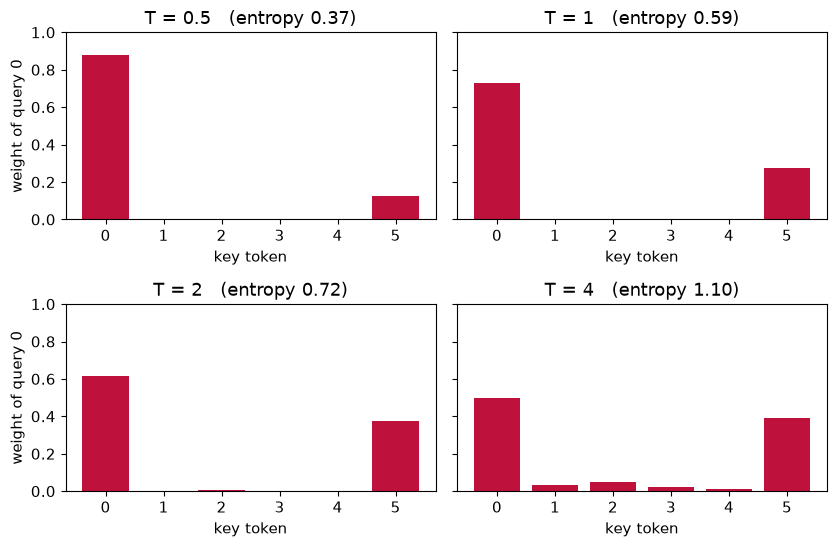

T = 0.5  entropy = 0.374   (max possible = log 6 = 1.792)
T = 1    entropy = 0.587   (max possible = log 6 = 1.792)
T = 2    entropy = 0.721   (max possible = log 6 = 1.792)
T = 4    entropy = 1.099   (max possible = log 6 = 1.792)
  ✓ entropy rises with temperature: higher T means flatter attention
  ✓ T = sqrt(d_k) is exactly the standard scaled attention


In [26]:
rng = np.random.default_rng(8)
Q7 = rng.normal(size=(6, 8))
K7 = rng.normal(size=(6, 8))
scores7 = Q7 @ K7.T                         # (6, 8) @ (8, 6) -> (6, 6), deliberately NOT divided by sqrt(d_k)
temperatures = [0.5, 1, 2, 4]


def entropy(p):
    """How spread out a distribution is: 0 = all on one token, log(n) = perfectly even."""
    return -np.sum(p * np.log(p + 1e-12))


fig, axes = plt.subplots(2, 2, figsize=(8.5, 5.6), sharey=True)   # 2 x 2 grid: one panel per temperature
entropies = []
for ax, T in zip(axes.ravel(), temperatures):
    weights_T = stable_softmax(scores7 / T, axis=-1)     # (6, 6)
    row = weights_T[0]                                   # query token 0
    entropies.append(entropy(row))
    ax.bar(range(6), row, color="#be123c")
    ax.set_title(f"T = {T}   (entropy {entropy(row):.2f})")
    ax.set_xlabel("key token")
    ax.set_ylim(0, 1)
for row_of_axes in axes:
    row_of_axes[0].set_ylabel("weight of query 0")
plt.tight_layout()
plt.savefig(OUT / "q7c_temperature.png", dpi=150)
plt.show()

for T, H_T in zip(temperatures, entropies):
    print(f"T = {T:<4} entropy = {H_T:.3f}   (max possible = log 6 = {np.log(6):.3f})")
check("entropy rises with temperature: higher T means flatter attention", np.all(np.diff(entropies) > 0))
_, w_scaled = scaled_dot_product_attention(Q7, K7, K7)
check("T = sqrt(d_k) is exactly the standard scaled attention", np.allclose(stable_softmax(scores7 / np.sqrt(8)), w_scaled))

### Q7(d) — evidence: a saturated softmax has almost no gradient

The derivative of softmax is $\dfrac{\partial s_i}{\partial z_j} = s_i(\delta_{ij} - s_j)$, i.e. the matrix $\text{diag}(s) - ss^\top$.

In [27]:
def softmax_jacobian(s):
    """The matrix of ds_i / dz_j for a softmax output s."""
    return np.diag(s) - np.outer(s, s)      # (n, n)

for z_test in [np.array([2.0, 1.0, 0.0]), np.array([20.0, 1.0, 0.0])]:
    s = stable_softmax(z_test)
    J = softmax_jacobian(s)
    print(f"scores {z_test} -> softmax {np.round(s, 4)} -> largest gradient entry {np.abs(J).max():.2e}")

scores [2. 1. 0.] -> softmax [0.6652 0.2447 0.09  ] -> largest gradient entry 2.23e-01
scores [20.  1.  0.] -> softmax [1. 0. 0.] -> largest gradient entry 7.66e-09


**What this shows (Q7):**
- Direct exponentiation of `[1000, 1001, 1002]` overflows to `inf`, and `inf / inf = nan`: the whole result is lost. The stable version gives `[0.090, 0.245, 0.665]`. This is the same answer as `[-2, -1, 0]`, because only **differences** between scores matter.
- **Temperature:** at T = 0.5 query 0 puts almost all its weight on one token (sharp, low entropy). At T = 4 the weights are nearly even (flat, high entropy). Dividing by √d_k is choosing T = √d_k.
- **Gradients:** with moderate scores the biggest gradient entry is about 0.22. With saturated scores (one weight ≈ 1) it is about $10^{-8}$, so the model gets almost **no learning signal**. Scaling by √d_k keeps the scores in the range where softmax can still learn.

---
## Q8 — Transformer encoder block from scratch

**Idea in one line:** attention lets tokens exchange information, the feed-forward network processes each token on its own, and each step is wrapped in "add the input back, then normalise".

$$H = \text{LayerNorm}(X + \text{MHA}(X)), \qquad Y = \text{LayerNorm}(H + \text{FFN}(H)), \qquad \text{FFN}(H) = \text{ReLU}(HW_1 + b_1)W_2 + b_2$$

**How we thought about it:** post-norm (normalise *after* the residual add), no dropout. LayerNorm normalises **each token across its features**. The block reuses `multi_head_attention` from Q6.

In [28]:
def layer_norm(X, gamma, beta, eps=1e-5):
    """Normalise each token (row) across its features, then rescale with gamma and shift with beta."""
    mean = X.mean(axis=-1, keepdims=True)                    # (n, 1): each token's own mean
    variance = ((X - mean) ** 2).mean(axis=-1, keepdims=True) # (n, 1): each token's own variance
    X_hat = (X - mean) / np.sqrt(variance + eps)             # (n, d): mean 0, variance about 1, per token
    return gamma * X_hat + beta                              # (n, d): gamma and beta are (d,)


def feed_forward(X, W1, b1, W2, b2):
    """Position-wise FFN: the same two-layer network applied to every token separately."""
    hidden = X @ W1 + b1             # (n, d) @ (d, d_ff) + (d_ff,) -> (n, d_ff)
    hidden = np.maximum(0.0, hidden) # ReLU: negative values become 0
    return hidden @ W2 + b2          # (n, d_ff) @ (d_ff, d) + (d,) -> (n, d)


def transformer_encoder_block(X, params):
    """Return (seq_len,d_model) output."""
    n, d_model = X.shape

    # Sub-layer 1: multi-head self-attention, then residual + LayerNorm
    attention_out, _ = multi_head_attention(X, params["W_Q"], params["W_K"], params["W_V"],
                                            params["W_O"], params["num_heads"])      # (n, d_model)
    assert attention_out.shape == (n, d_model)
    H = layer_norm(X + attention_out, params["gamma1"], params["beta1"])           # (n, d_model)

    # Sub-layer 2: feed-forward, then residual + LayerNorm
    ffn_out = feed_forward(H, params["W1"], params["b1"], params["W2"], params["b2"])  # (n, d_model)
    assert ffn_out.shape == (n, d_model)
    Y = layer_norm(H + ffn_out, params["gamma2"], params["beta2"])                 # (n, d_model)
    return Y


def random_matrix(rng, rows, cols):
    """A random weight matrix, scaled so outputs stay around size 1."""
    return rng.normal(size=(rows, cols)) / np.sqrt(rows)


def make_encoder_params(d_model, num_heads, d_ff, rng):
    return {
        "num_heads": num_heads,
        "W_Q": random_matrix(rng, d_model, d_model), "W_K": random_matrix(rng, d_model, d_model),
        "W_V": random_matrix(rng, d_model, d_model), "W_O": random_matrix(rng, d_model, d_model),
        "gamma1": np.ones(d_model), "beta1": np.zeros(d_model),
        "W1": random_matrix(rng, d_model, d_ff), "b1": np.zeros(d_ff),
        "W2": random_matrix(rng, d_ff, d_model), "b2": np.zeros(d_model),
        "gamma2": np.ones(d_model), "beta2": np.zeros(d_model),
    }

### Q8(b) — running the block, with tests

In [29]:
rng = np.random.default_rng(9)
n, d_model, num_heads, d_ff = 5, 8, 2, 32
X8 = rng.normal(size=(n, d_model)) + sinusoidal_positional_encoding(n, d_model)   # word vectors + positions
enc_params = make_encoder_params(d_model, num_heads, d_ff, rng)

Y8 = transformer_encoder_block(X8, enc_params)
show("encoder block output", Y8)
check("encoder output keeps the shape (seq_len, d_model) = (5, 8)", Y8.shape == (5, 8))
print("per-token mean    :", Y8.mean(axis=1))
print("per-token variance:", Y8.var(axis=1))
check("LayerNorm: every token has mean 0", np.allclose(Y8.mean(axis=1), 0.0, atol=1e-9))
check("LayerNorm: every token has variance 1 (eps shrinks it very slightly)", np.allclose(Y8.var(axis=1), 1.0, atol=1e-3))

encoder block output   shape (5, 8)
[[-0.7482  0.4746 -1.0196  1.7059 -0.1092 -1.3585  1.1798 -0.1248]
 [-0.0457 -0.9633 -0.1044  2.3762 -1.171  -0.1778  0.0983 -0.0124]
 [ 0.123  -0.4812  0.1723  1.76   -1.1802 -1.4004 -0.1154  1.1218]
 [ 0.2625 -1.1156  1.7676  0.509   0.2613 -1.7965  0.0797  0.032 ]
 [-1.0811 -0.7923  0.8849  2.0661 -0.6387 -0.8166  0.1342  0.2435]]

  ✓ encoder output keeps the shape (seq_len, d_model) = (5, 8)
per-token mean    : [ 0.  0. -0.  0. -0.]
per-token variance: [1. 1. 1. 1. 1.]
  ✓ LayerNorm: every token has mean 0
  ✓ LayerNorm: every token has variance 1 (eps shrinks it very slightly)


### Q8(c) — evidence: the FFN works per token, attention mixes tokens

In [30]:
X8_changed = X8.copy()
X8_changed[1] = X8_changed[1] + 5.0          # change ONLY the 2nd token

p = enc_params
ffn_before = feed_forward(X8, p["W1"], p["b1"], p["W2"], p["b2"])
ffn_after = feed_forward(X8_changed, p["W1"], p["b1"], p["W2"], p["b2"])
ffn_rows_changed = ~np.all(np.isclose(ffn_before, ffn_after), axis=1)

attn_before, _ = multi_head_attention(X8, p["W_Q"], p["W_K"], p["W_V"], p["W_O"], p["num_heads"])
attn_after, _ = multi_head_attention(X8_changed, p["W_Q"], p["W_K"], p["W_V"], p["W_O"], p["num_heads"])
attn_rows_changed = ~np.all(np.isclose(attn_before, attn_after), axis=1)

print("rows whose FFN output changed      :", ffn_rows_changed)
print("rows whose attention output changed:", attn_rows_changed)
check("FFN: only the changed token's row moves", ffn_rows_changed.tolist() == [False, True, False, False, False])
check("attention: every token's row moves", np.all(attn_rows_changed))

rows whose FFN output changed      : [False  True False False False]
rows whose attention output changed: [ True  True  True  True  True]
  ✓ FFN: only the changed token's row moves
  ✓ attention: every token's row moves


**What this shows (Q8):**
- The block keeps the shape **(n × d_model)** end to end, which is why blocks can be stacked N times.
- **Attention mixes tokens:** changing token 2 changed every row of the attention output. **The FFN is position-wise:** the same weights are applied to each row separately, so only row 2 changed.
- **LayerNorm** brought every token to mean 0 and variance 1 (minus a tiny bit because of ε), which keeps values in a stable range from layer to layer.
- **Residual paths:** each sub-layer computes $x + F(x)$, whose gradient is $I + \partial F/\partial x$. The identity term gives the gradient a direct path backwards through every layer, so it cannot vanish the way it did through the RNN's repeated multiplications (a4).

---
## Q9 — Transformer decoder block and the complete architecture

**Idea in one line:** the decoder block has three sub-layers, each followed by residual + LayerNorm: masked self-attention (only earlier output words), cross-attention (the source sentence), and the feed-forward network.

**How we thought about it:** reuse `mha_general` twice. With `causal=True` it is masked self-attention; with `X_kv = encoder_output` it is cross-attention. Every intermediate shape is asserted.

In [31]:
def make_decoder_params(d_model, num_heads, d_ff, rng):
    return {
        "num_heads": num_heads,
        "self_W_Q": random_matrix(rng, d_model, d_model), "self_W_K": random_matrix(rng, d_model, d_model),
        "self_W_V": random_matrix(rng, d_model, d_model), "self_W_O": random_matrix(rng, d_model, d_model),
        "gamma1": np.ones(d_model), "beta1": np.zeros(d_model),
        "cross_W_Q": random_matrix(rng, d_model, d_model), "cross_W_K": random_matrix(rng, d_model, d_model),
        "cross_W_V": random_matrix(rng, d_model, d_model), "cross_W_O": random_matrix(rng, d_model, d_model),
        "gamma2": np.ones(d_model), "beta2": np.zeros(d_model),
        "W1": random_matrix(rng, d_model, d_ff), "b1": np.zeros(d_ff),
        "W2": random_matrix(rng, d_ff, d_model), "b2": np.zeros(d_model),
        "gamma3": np.ones(d_model), "beta3": np.zeros(d_model),
    }


def transformer_decoder_block(decoder_input, encoder_output, params, verbose=False):
    """Return decoder output after masked attention,
    cross-attention and feed-forward layers."""
    p = params
    n, d_model = decoder_input.shape          # n = decoder length
    m = encoder_output.shape[0]               # m = encoder length
    H = p["num_heads"]

    # (1) masked self-attention: each output word sees only itself and earlier output words
    A, w_self = mha_general(decoder_input, decoder_input, p["self_W_Q"], p["self_W_K"], p["self_W_V"],
                            p["self_W_O"], H, causal=True)                      # (n, d_model), (H, n, n)
    assert A.shape == (n, d_model) and w_self.shape == (H, n, n)
    # (2) residual + norm
    H1 = layer_norm(decoder_input + A, p["gamma1"], p["beta1"])                 # (n, d_model)

    # (3) cross-attention: queries from the decoder, keys and values from the encoder
    C, w_cross = mha_general(H1, encoder_output, p["cross_W_Q"], p["cross_W_K"], p["cross_W_V"],
                             p["cross_W_O"], H, causal=False)                   # (n, d_model), (H, n, m)
    assert C.shape == (n, d_model) and w_cross.shape == (H, n, m)
    # (4) residual + norm
    H2 = layer_norm(H1 + C, p["gamma2"], p["beta2"])                            # (n, d_model)

    # (5) position-wise feed-forward
    F = feed_forward(H2, p["W1"], p["b1"], p["W2"], p["b2"])                    # (n, d_model)
    assert F.shape == (n, d_model)
    # (6) residual + norm
    Y = layer_norm(H2 + F, p["gamma3"], p["beta3"])                             # (n, d_model)

    if verbose:
        print(f"decoder input              {decoder_input.shape}")
        print(f"encoder output             {encoder_output.shape}")
        print(f"(1) masked self-attn wts   {w_self.shape}   out {A.shape}")
        print(f"(2) residual + norm        {H1.shape}")
        print(f"(3) cross-attn weights     {w_cross.shape}   out {C.shape}")
        print(f"(4) residual + norm        {H2.shape}")
        print(f"(5) FFN                    hidden {(n, p['W1'].shape[1])}   out {F.shape}")
        print(f"(6) residual + norm = Y    {Y.shape}")
    return Y

### Q9(b) — d_model = 8, 2 heads, encoder length 5, decoder length 3

In [32]:
rng = np.random.default_rng(10)
d_model, num_heads, d_ff = 8, 2, 32
src_len, tgt_len = 5, 3

source = rng.normal(size=(src_len, d_model)) + sinusoidal_positional_encoding(src_len, d_model)
target = rng.normal(size=(tgt_len, d_model)) + sinusoidal_positional_encoding(tgt_len, d_model)

enc_params9 = make_encoder_params(d_model, num_heads, d_ff, rng)
dec_params9 = make_decoder_params(d_model, num_heads, d_ff, rng)

encoder_output = transformer_encoder_block(source, enc_params9)                  # (5, 8)
Y9 = transformer_decoder_block(target, encoder_output, dec_params9, verbose=True)

check("encoder output is (5, 8)", encoder_output.shape == (5, 8))
check("decoder output is (3, 8): one row per DECODER token", Y9.shape == (3, 8))

# No future leak: change the LAST decoder token; rows 1 and 2 must not move
target_changed = target.copy()
target_changed[-1] = target_changed[-1] + 5.0
Y9_future = transformer_decoder_block(target_changed, encoder_output, dec_params9)
check("changing a future decoder token leaves earlier decoder rows unchanged", np.allclose(Y9[:-1], Y9_future[:-1]))

# Cross-attention reaches everywhere: change ONE source token; every decoder row should move
source_changed = source.copy()
source_changed[2] = source_changed[2] + 5.0
Y9_source = transformer_decoder_block(target, transformer_encoder_block(source_changed, enc_params9), dec_params9)
rows_moved = ~np.all(np.isclose(Y9, Y9_source), axis=1)
print("decoder rows that moved after changing source token 3:", rows_moved)
check("changing one source token moves every decoder row (via cross-attention)", np.all(rows_moved))

decoder input              (3, 8)
encoder output             (5, 8)
(1) masked self-attn wts   (2, 3, 3)   out (3, 8)
(2) residual + norm        (3, 8)
(3) cross-attn weights     (2, 3, 5)   out (3, 8)
(4) residual + norm        (3, 8)
(5) FFN                    hidden (3, 32)   out (3, 8)
(6) residual + norm = Y    (3, 8)
  ✓ encoder output is (5, 8)
  ✓ decoder output is (3, 8): one row per DECODER token
  ✓ changing a future decoder token leaves earlier decoder rows unchanged
decoder rows that moved after changing source token 3: [ True  True  True]
  ✓ changing one source token moves every decoder row (via cross-attention)


### The complete architecture, end to end (tiny, untrained)

Token ids → embedding + positional encoding → encoder block → decoder block → linear projection to the vocabulary → softmax. The weights are random, so the predicted words mean nothing. The point is the shapes and the flow.

In [33]:
rng = np.random.default_rng(11)
vocab_size = 10
embedding_table = rng.normal(size=(vocab_size, d_model))     # (vocab, d_model): one row per word id
W_vocab = random_matrix(rng, d_model, vocab_size)           # (d_model, vocab): final projection

source_ids = np.array([1, 4, 2, 7, 3])                       # 5 source words
target_ids = np.array([0, 5, 6])                             # start token + 2 words written so far

src = embedding_table[source_ids] + sinusoidal_positional_encoding(5, d_model)   # (5, 8)
tgt = embedding_table[target_ids] + sinusoidal_positional_encoding(3, d_model)   # (3, 8)
memory = transformer_encoder_block(src, enc_params9)                            # (5, 8)
dec_out = transformer_decoder_block(tgt, memory, dec_params9)                   # (3, 8)
logits = dec_out @ W_vocab                                                      # (3, 8) @ (8, 10) -> (3, 10)
probs = softmax(logits, axis=-1)                                                # (3, 10)

print("logits shape:", logits.shape, "   probabilities shape:", probs.shape)
print("most likely next word id at each decoder position:", np.argmax(probs, axis=1))
check("vocabulary projection gives one distribution per decoder position, (3, 10)", probs.shape == (3, 10))
check("each distribution over the vocabulary sums to 1", np.allclose(probs.sum(axis=1), 1.0))

logits shape: (3, 10)    probabilities shape: (3, 10)
most likely next word id at each decoder position: [0 0 1]
  ✓ vocabulary projection gives one distribution per decoder position, (3, 10)
  ✓ each distribution over the vocabulary sums to 1


**What this shows (Q9):**
- Every shape checks out: decoder (3 × 8) and encoder (5 × 8) in, self-attention weights (2 × 3 × 3), cross-attention weights **(2 × 3 × 5)**, decoder output (3 × 8), then (3 × 10) word probabilities.
- **Masked self-attention** (decoder looks at its own earlier words) vs **encoder–decoder attention** (decoder looks at the source): the future-leak test shows the first is causal, and the source test shows the second reaches every decoder position.
- **Information flow:** source words → embedding + PE → encoder → K and V of every cross-attention → decoder → linear → softmax → next word.
- **Why only the decoder is masked:** the encoder reads a sentence that already exists in full. The decoder generates one word at a time, so during training it must not see the words it is about to predict.

---
## Q10 — Computational complexity

**Idea in one line:** every token scores against every token, so attention grows with $n^2$. The projections grow only with $n$, so for short sequences they dominate, and $n^2$ takes over past $n = 2\,d_{model}$.

| operation | one head | all H heads ($H d_k = d$) |
|---|---|---|
| Q, K, V projections | $3\,n\,d\,d_k$ | $3\,n\,d^2$ |
| scores $QK^\top$ | $n^2 d_k$ | $n^2 d$ |
| weights × V | $n^2 d_v$ | $n^2 d$ |
| attention matrix memory | $n^2$ | $H n^2$ |

(counted in multiply-adds; with $W_O$ the projections total $4nd^2$ against $2n^2d$ for attention, equal at $n = 2d$)

In [34]:
def benchmark_attention(seq_lengths, d_model, num_heads, repeats=9):
    """Report timing and attention-matrix memory."""
    rng = np.random.default_rng(12)
    W_Q = random_matrix(rng, d_model, d_model)
    W_K = random_matrix(rng, d_model, d_model)
    W_V = random_matrix(rng, d_model, d_model)
    W_O = random_matrix(rng, d_model, d_model)

    results = []
    for n in seq_lengths:
        X = rng.normal(size=(n, d_model))
        multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads)          # warm-up run, not timed

        times = []
        for _ in range(repeats):
            start = time.perf_counter()
            _, weights = multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads)   # output not needed here
            times.append(time.perf_counter() - start)

        results.append({
            "n": n,
            "time_ms": np.median(times) * 1000,                  # median: robust to one slow run
            "memory_bytes": num_heads * n * n * 8,               # H matrices of n x n float64 (8 bytes each)
            "actual_weight_bytes": weights.nbytes,               # what NumPy really allocated
            "projection_macs": 4 * n * d_model * d_model,        # Q, K, V and O projections
            "attention_macs": 2 * n * n * d_model,               # QK^T plus weights @ V, all heads
        })
    return results


seq_lengths = [32, 64, 128, 256, 512]
bench = benchmark_attention(seq_lengths, d_model=64, num_heads=4)

print("   n   time (ms)   attn memory   projection MACs   attention MACs")
for r in bench:
    print(f"{r['n']:>4} {r['time_ms']:>10.3f} {r['memory_bytes'] / 1024:>10.0f} KiB"
          f" {r['projection_macs']:>16,} {r['attention_macs']:>16,}")

check("memory formula H*n^2*8 bytes equals what NumPy actually allocated, for every n",
      all(r["memory_bytes"] == r["actual_weight_bytes"] for r in bench))

   n   time (ms)   attn memory   projection MACs   attention MACs
  32      0.069         32 KiB          524,288          131,072
  64      0.127        128 KiB        1,048,576          524,288
 128      0.310        512 KiB        2,097,152        2,097,152
 256      0.933       2048 KiB        4,194,304        8,388,608
 512      3.621       8192 KiB        8,388,608       33,554,432
  ✓ memory formula H*n^2*8 bytes equals what NumPy actually allocated, for every n


slope of log(time) vs log(n) between neighbouring sizes (2 would mean pure n^2):
   32 -> 64   measured 0.89   arithmetic alone 1.26
   64 -> 128  measured 1.28   arithmetic alone 1.42
  128 -> 256  measured 1.59   arithmetic alone 1.58
  256 -> 512  measured 1.96   arithmetic alone 1.74


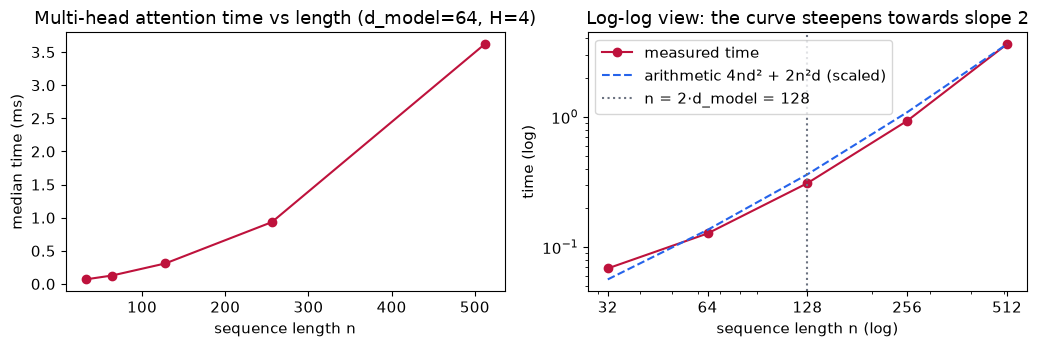

In [35]:
times = np.array([r["time_ms"] for r in bench])
theory = np.array([r["projection_macs"] + r["attention_macs"] for r in bench], dtype=float)
n_values = np.array(seq_lengths, dtype=float)

print("slope of log(time) vs log(n) between neighbouring sizes (2 would mean pure n^2):")
for a in range(len(seq_lengths) - 1):
    measured = np.log(times[a + 1] / times[a]) / np.log(n_values[a + 1] / n_values[a])
    theoretical = np.log(theory[a + 1] / theory[a]) / np.log(n_values[a + 1] / n_values[a])
    print(f"  {seq_lengths[a]:>3} -> {seq_lengths[a + 1]:<3}  measured {measured:.2f}   arithmetic alone {theoretical:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].plot(seq_lengths, times, marker="o", color="#be123c")
axes[0].set_xlabel("sequence length n")
axes[0].set_ylabel("median time (ms)")
axes[0].set_title("Multi-head attention time vs length (d_model=64, H=4)")

axes[1].loglog(seq_lengths, times, marker="o", color="#be123c", label="measured time")
axes[1].loglog(seq_lengths, theory / theory[-1] * times[-1], linestyle="--", color="#2563eb",
               label="arithmetic 4nd² + 2n²d (scaled)")
axes[1].axvline(2 * 64, color="#6b7280", linestyle=":", label="n = 2·d_model = 128")
axes[1].set_xticks(seq_lengths)                                  # label only the 5 lengths we timed
axes[1].set_xticklabels([str(n) for n in seq_lengths])
axes[1].xaxis.set_minor_formatter(plt.NullFormatter())           # hide the cluttered minor labels
axes[1].set_xlabel("sequence length n (log)")
axes[1].set_ylabel("time (log)")
axes[1].set_title("Log-log view: the curve steepens towards slope 2")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "q10b_benchmark.png", dpi=150)
plt.show()

**What this shows (Q10):**
- **Memory is exactly quadratic:** 32 KiB at n = 32 up to 8 MiB at n = 512. The text got 16× longer and the attention matrices got 256× (= 16²) bigger. The formula matched NumPy's real allocation at every size.
- **Time steepens.** At small n the projections ($4nd^2$) cost more arithmetic than attention ($2n^2d$), so even the pure arithmetic grows more slowly than $n^2$. Past $n = 2d = 128$ the $n^2$ term takes over and the slope approaches 2. Where the measured slope differs from the arithmetic slope, that is the **implementation**: fixed Python overhead at small n, and memory traffic at large n.
- **Masking:** our causal attention still computes the full $n \times n$ score matrix and then blanks half of it, so it saves **no arithmetic**. Only specialised kernels that skip the blocked half get the saving. That is the difference between arithmetic cost and implementation-level savings.
- **Heads:** splitting into H heads keeps the arithmetic the same ($H \cdot d_k = d$) but stores H separate $n \times n$ matrices.

---
## Export: every hand-calculation value, for checking the handwritten notes

`check_draft_numbers.py` compares every number in the typed draft of the handwritten notes with these values, so nothing unverified ends up on paper.

In [36]:
import json


def finite_values(*arrays):
    """Flatten any number of arrays into one list of plain floats, skipping -inf (masked entries)."""
    values = []
    for array in arrays:
        for value in np.asarray(array, dtype=float).ravel():
            if np.isfinite(value):
                values.append(float(value))
    return values


# Recompute every hand calculation from the functions above, keeping all intermediate steps
q2 = attention_steps(np.eye(2), np.eye(2), np.eye(2))
q3 = attention_steps(Q3, K3, V3)
q3_identity = attention_steps(X3, X3, X3)
q4 = attention_steps(Z, Z, Z, mask=causal_mask(3))
q5 = attention_steps(Q5, K5, V5)
divisors_d4 = 10000 ** (2 * np.arange(2) / 4)
z_shifted = z - z.max()

verified = {
    "constants": finite_values([np.sqrt(2), 1 / np.sqrt(2), np.exp(1 / np.sqrt(2)), np.exp(np.sqrt(2)),
                                2 * np.pi, 1.0]),
    "Q1": finite_values(divisors_d4, np.arange(3).reshape(-1, 1) / divisors_d4, pe_small,
                        2 * np.pi * divisors_d4, wavelengths),
    "Q2": finite_values(*q2.values(), q2["weights"].sum(axis=1)),
    "Q3": finite_values(Q3, K3, V3, *q3.values(), *q3_identity.values(),
                        q3_identity["scaled"][:, 0] - q3_identity["scaled"][:, 1]),
    "Q4": finite_values(*q4.values(), np.round(q4["weights"], 3).sum(axis=1)),
    "Q5": finite_values(*q5.values()),
    "Q6": finite_values(w_toy, concat_toy),
    "Q7": finite_values(z_shifted, np.exp(z_shifted), np.exp(z_shifted).sum(), stable_result,
                        entropies, temperatures,
                        np.abs(softmax_jacobian(stable_softmax(np.array([2.0, 1.0, 0.0])))).max()),
    "Q8": [],
    "Q9": [],
    "Q10": finite_values([r["memory_bytes"] / 1024 for r in bench]),
}
(OUT / "verified_values.json").write_text(json.dumps(verified, indent=1))
for key, values in verified.items():
    print(f"{key:<10} {len(values):>3} values")

constants    6 values
Q1          30 values
Q2          24 values
Q3          58 values
Q4          54 values
Q5          15 values
Q6          16 values
Q7          19 values
Q8           0 values
Q9           0 values
Q10          5 values


---
## Verification summary

In [37]:
passed = sum(1 for _, ok in CHECKS if ok)
print(f"All checks: {passed}/{len(CHECKS)} passed")
for name, ok in CHECKS:
    if not ok:
        print("  FAILED:", name)

All checks: 73/73 passed
